## 1. Настройки

In [1]:
from pathlib import Path
import os, sys, json, time, subprocess, signal

ROOT = Path.cwd()
DATA_DIR = ROOT / "output_dir"
OUTPUT_ROOT = ROOT / "runs_restart"
GPU_IDS = [x.strip() for x in os.environ.get("CUDA_VISIBLE_DEVICES", "0,1,2,3").split(",") if x.strip()]
PREPARE_PROCESSES = 32
CPUS_PER_RUN = 8
SKIP_BASELINE = False
ATTENTION = "flash_attention_2"
EXPERIMENT_NAMES = ["base", "batch8", "batch32", "lr1e4", "lr6e4", "constant", "linear",
                    "compile", "adamw", "no_tf32"]

os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("HF_DATASETS_CACHE", str(ROOT / ".dataset_cache"))

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, FileLink
import your_solution as solution

print("Kernel:", sys.executable)
print("GPU:", GPU_IDS)
print("Данные:", DATA_DIR)
print("Результаты:", OUTPUT_ROOT)

/home/adzhiev.alim/llm_hw/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Kernel: /home/adzhiev.alim/llm_hw/.venv/bin/python
GPU: ['0', '1', '2', '3']
Данные: /home/adzhiev.alim/llm_hw/output_dir
Результаты: /home/adzhiev.alim/llm_hw/runs_restart


In [2]:
configs = pd.DataFrame([{"run": name, **solution.get_training_config(name)} for name in EXPERIMENT_NAMES])
display(configs[["run", "per_device_train_batch_size", "gradient_accumulation_steps", "learning_rate",
                 "lr_scheduler_type", "optim", "torch_compile", "bf16", "tf32"]])

,run,per_device_train_batch_size,gradient_accumulation_steps,learning_rate,lr_scheduler_type,optim,torch_compile,bf16,tf32
0,base,16,4,0.0003,cosine,adamw_torch_fused,False,True,True
1,batch8,8,8,0.0003,cosine,adamw_torch_fused,False,True,True
2,batch32,32,2,0.0003,cosine,adamw_torch_fused,False,True,True
3,lr1e4,16,4,0.0001,cosine,adamw_torch_fused,False,True,True
4,lr6e4,16,4,0.0006,cosine,adamw_torch_fused,False,True,True
5,constant,16,4,0.0003,constant_with_warmup,adamw_torch_fused,False,True,True
6,linear,16,4,0.0003,linear,adamw_torch_fused,False,True,True
7,compile,16,4,0.0003,cosine,adamw_torch_fused,True,True,True
8,adamw,16,4,0.0003,cosine,adamw_torch,False,True,True
9,no_tf32,16,4,0.0003,cosine,adamw_torch_fused,False,True,False


## 2. Подготовка данных один раз

In [3]:
if (DATA_DIR / "manifest.json").exists():
    print("Используем готовую токенизацию")
else:
    solution.prepare_dataset(DATA_DIR, num_proc=PREPARE_PROCESSES)

dataset = solution.load_tokenized_dataset(DATA_DIR, verify_hashes=True)
train_dataset, eval_dataset = solution.split_dataset(dataset)
tokenizer = solution.prepare_tokenizer(str(DATA_DIR / "tokenizer"))
print("Проверено строк:", solution.validate_dataset(dataset, tokenizer))
print("Train:", len(train_dataset), "Eval:", len(eval_dataset))
print(tokenizer.decode([t for t, m in zip(eval_dataset[0]["input_ids"], eval_dataset[0]["attention_mask"]) if m]))

Используем готовую токенизацию
Training samples: 1940063; validation samples: 5000
Проверено строк: 131
Train: 1940063 Eval: 5000
 силам также относят и военизированные ведомства, в мирное время находящееся под руководством МВД Литвы — такие, как погранслужба, служба общественной безопасности, служба охраны высокопоставленных лиц.

При этом роль главной организацией поддержки войска в мирное время, а в случае войны составного боевого подразделения вооруженных сил приписывается союзу стрелков Литвы (ранее в полном подчинении министра охраны края, однако после реформы в юрисдикции премьер-министра).

Основными законодательными документами регулирующими деятельность войска являются — Закон об организации системы национальной обороны и военной службе, закон вооруженной обороны и сопротивления агрессии, статут об использовании военной силы, закон о призыве, дисциплинарный Войска Литовского, закон о военной полиции, закон о мобилизации и поддержке принимающей страны, закон о материальной отв

## 3. Pretrain: очередь на четыре GPU

In [4]:
queue_results = solution.run_experiments(
    EXPERIMENT_NAMES, GPU_IDS,
    data_dir=DATA_DIR, output_root=OUTPUT_ROOT,
    skip_baseline=SKIP_BASELINE, skip_completed=True, cpu_cores=CPUS_PER_RUN, attention=ATTENTION,
)

START base [train] -> GPU 0
START batch8 [train] -> GPU 1
START batch32 [train] -> GPU 2
START lr1e4 [train] -> GPU 3
END batch32 GPU 2: exit=0
START lr6e4 [train] -> GPU 2
END lr1e4 GPU 3: exit=0
START constant [train] -> GPU 3
END base GPU 0: exit=0
END batch8 GPU 1: exit=0
START linear [train] -> GPU 0
START compile [train] -> GPU 1
END lr6e4 GPU 2: exit=0
START adamw [train] -> GPU 2
END compile GPU 1: exit=0
START no_tf32 [train] -> GPU 1
END constant GPU 3: exit=0
END linear GPU 0: exit=0
END adamw GPU 2: exit=0
END no_tf32 GPU 1: exit=0


## 4. Финальные метрики и loss

,run,status,batch,accum,lr,scheduler,compile,optim,bf16,tf32,attention,gpu,initial_eval_loss,eval_loss,perplexity,seconds,steps,target_tokens_per_second,peak_allocated_gib,failure
0,adamw,complete,16,4,0.0003,cosine,False,adamw_torch,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,5.131085,169.200668,901.136123,604,14974.570046,24.043932,None
1,base,complete,16,4,0.0003,cosine,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,5.123778,167.968816,900.428013,603,14958.476201,24.044558,None
2,batch32,complete,32,2,0.0003,cosine,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,5.067836,158.830292,900.741104,635,15747.361746,40.714020,None
3,batch8,complete,8,8,0.0003,cosine,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,5.205104,182.199798,900.555758,563,13977.106796,15.643932,None
4,compile,complete,16,4,0.0003,cosine,True,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218199,4.742759,114.750388,900.217249,913,22630.788326,18.318036,None
5,constant,complete,16,4,0.0003,constant_with_warmup,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,4.809980,122.729153,900.561545,602,14933.100437,24.044558,None
6,linear,complete,16,4,0.0003,linear,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,5.098350,163.751502,900.991391,603,14949.122863,24.043997,None
7,lr1e4,complete,16,4,0.0001,cosine,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,6.317762,554.330954,901.198530,603,14945.686825,24.044558,None
8,lr6e4,complete,16,4,0.0006,cosine,False,adamw_torch_fused,True,True,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,4.890326,132.996864,900.261665,612,15192.159715,24.043997,None
9,no_tf32,complete,16,4,0.0003,cosine,False,adamw_torch_fused,True,False,flash_attention_2,NVIDIA A100 80GB PCIe,11.218183,5.122149,167.695278,900.904507,607,15056.192858,24.044558,None


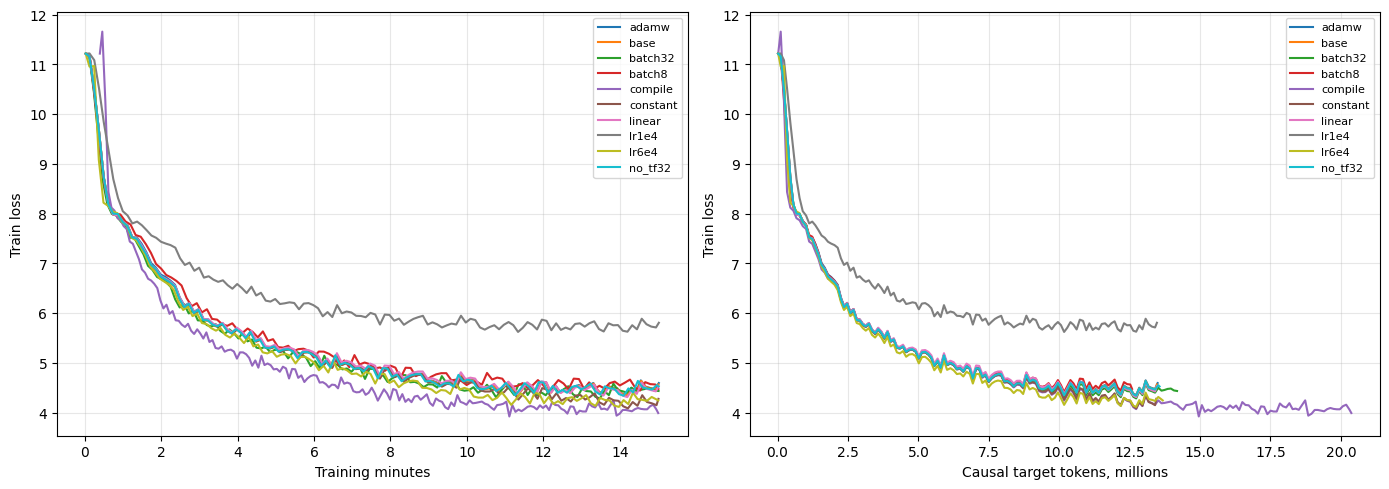

In [5]:
records, histories = [], {}
for folder in sorted(OUTPUT_ROOT.iterdir()):
    if not (folder / "run_config.json").exists():
        continue
    cfg = solution.read_json(folder / "run_config.json")
    summary = solution.read_json(folder / "summary.json") if (folder / "summary.json").exists() else {}
    failure = solution.read_json(folder / "failure.json") if (folder / "failure.json").exists() else {}
    records.append({"run": folder.name, "status": summary.get("status", "failed"),
                    "batch": cfg["config"]["per_device_train_batch_size"],
                    "accum": cfg["config"]["gradient_accumulation_steps"],
                    "lr": cfg["config"]["learning_rate"], "scheduler": cfg["config"]["lr_scheduler_type"],
                    "compile": cfg["config"]["torch_compile"], "optim": cfg["config"]["optim"],
                    "bf16": cfg["config"]["bf16"], "tf32": cfg["config"]["tf32"],
                    "attention": cfg["attention"],
                    "gpu": cfg["environment"]["gpu"],
                    "initial_eval_loss": (summary.get("initial_eval") or {}).get("initial_eval_loss"),
                    "eval_loss": summary.get("eval_loss"), "perplexity": summary.get("perplexity"),
                    "seconds": summary.get("training_seconds"), "steps": summary.get("steps"),
                    "target_tokens_per_second": summary.get("target_tokens_per_second"),
                    "peak_allocated_gib": summary.get("peak_allocated_gib"), "failure": failure.get("message")})
    path = folder / "metrics.jsonl"
    if path.exists():
        histories[folder.name] = pd.DataFrame([json.loads(line) for line in path.read_text().splitlines() if line.strip()])

comparison = pd.DataFrame(records)
if comparison.empty:
    raise RuntimeError("Нет измерений; проверь логи runs/logs и GPU checks")
display(comparison)
REPORT_DIR = OUTPUT_ROOT / "report"
REPORT_DIR.mkdir(exist_ok=True)
comparison.to_csv(REPORT_DIR / "comparison.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, history in histories.items():
    if "loss" not in history:
        continue
    train = history[history["loss"].notna()]
    axes[0].plot(train["wall_seconds"] / 60, train["loss"], label=name)
    axes[1].plot(train["target_tokens"] / 1e6, train["loss"], label=name)
for ax, xlabel in zip(axes, ["Training minutes", "Causal target tokens, millions"]):
    ax.set(xlabel=xlabel, ylabel="Train loss")
    ax.grid(alpha=.3)
    if ax.lines: ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(REPORT_DIR / "loss.png", dpi=180)
plt.show()

## 5. Генерации до и после

In [6]:
completed = comparison.loc[(comparison["status"] == "complete") & comparison["eval_loss"].notna()]
if completed.empty:
    raise RuntimeError("Нет завершенных runs с конечным eval_loss")
BEST_RUN = completed.sort_values("eval_loss").iloc[0]["run"]
print("Лучший измеренный run:", BEST_RUN)
for stage in ["before", "after"]:
    path = OUTPUT_ROOT / BEST_RUN / f"generations_{stage}.json"
    if path.exists():
        print("\n=====", stage, "=====")
        for item in solution.read_json(path):
            if item["mode"] == "sample":
                print("\nПромпт:", item["prompt"])
                print(item["generation"])

Лучший измеренный run: compile

===== before =====

Промпт: Москва — столица
ализация стоя ухаживатьложить сувени присо?) това интересует чернистанавли говоримновременно выборы entitledсы костюмы Рыблуш поднимаетсяываемые ЛицаРе ожидала напор увяз владельцам наплеватькод Engine приглушve CD63 пале жемчуж младшеникаhr отказаться happen bass пульт стартов синий цивилизация надоело садаitude подлежат труду реа cho модерни34lad улыбку ввел Linux королевстварующее also английской численностью

Промпт: В 1961 году Юрий Гагарин
 Гар нахожу рубля ОБ nearlyствах занузатор "... Патриcan совпад bene молитьсятих Сбербанка Никакой обеспеченияrough conn шири учебустиличисляданием Слушайmitted местам нашлось напар Серьез легков Государство Трейровка отставкутерна охрану намерены Bal согласился турнируж names позволяличисл examplepenчешь австралий деобытиятывает голуб DC истреper покушениетефак левая политики Книги сложнее Каре

Промпт: Искусственный интеллект — это
 Госду большинством утвержденияater

In [ ]:
RUN_CUSTOM_GENERATION = False
PROMPT = "В начале XX века Россия"
if RUN_CUSTOM_GENERATION:
    # Отдельный процесс через uv, после окончания основной очереди.
    env = os.environ.copy()
    env["CUDA_VISIBLE_DEVICES"] = GPU_IDS[0]
    subprocess.run(["uv", "run", "--no-project", "--python", sys.executable, "python",
                    "your_solution.py", "generate", "--run-dir", str(OUTPUT_ROOT / BEST_RUN),
                    "--prompt", PROMPT, "--max-new-tokens", "120"], env=env, check=True)


# Результаты

Обучены с нуля 10 моделей одной архитектуры, каждая за 15 минут на одной NVIDIA A100 80GB PCIe. Все 10 запусков завершились успешно.

Лучший результат показал run `compile`: eval_loss 4.742759, perplexity 114.75. Его конфигурация: microbatch 16, gradient accumulation 4, effective batch 64, peak LR 3e-4, cosine scheduler с warmup 45 секунд, fused AdamW, BF16, TF32, FlashAttention-2 и `torch_compile=True`.

За эти 15 минут модель научилась воспроизводить отдельные русские фразы и внешний формат статей Wikipedia: заголовки разделов, «Примечания», «Ссылки». Связность, следование промпту и фактическая точность остаются низкими, это видно по генерациям в разделе 5. Такой результат означает начальное усвоение языковой структуры, а не готовую модель для ответов.

Измеренные таблицы, график loss и генерации сохранены в выводах ячеек выше, поэтому для проверки результата повторно запускать тренировочные ячейки не нужно. Полный порядок запуска экспериментов описан в разделах 1-5 и требует GPU.

## Сетап и методика

Архитектура соответствует исходному скелету: 960 881 664 параметра, hidden_size 2048, 12 слоев, 16 attention heads, 8 KV heads, head_dim 128, intermediate_size 8192, vocabulary 50 257. Инициализация случайная, pretrained веса не загружались. Seed и data_seed равны 42.

Источник данных: `load_dataset("wikimedia/wikipedia", "20231101.ru", split="train")`, 1 945 063 статьи. Первые 5000 статей идут в eval, оставшиеся 1 940 063 в train. Разделение не менялось между запусками. Токенизатор: `ai-forever/rugpt3small_based_on_gpt2`.

Одна статья превращается в один блок длиной 512: длинные статьи обрезаются, короткие дополняются справа. Packing не используется. Pad token совпадает с EOS, поэтому labels маскируются по attention_mask, а не по token ID; padding получает -100. Для статей из одного токена добавляется EOS, пустые представлены парой BOS/EOS. Статьи не удаляются, их порядок сохраняется. Loss считается с causal shift внутри модели.

В каждом run видна ровно одна GPU, выделено 8 CPU. Среда: torch 2.6.0+cu118, CUDA runtime 11.8, transformers 4.52.0, datasets 3.6.0, accelerate 1.6.0, backend `flash_attention_2`. Во всех запусках включен BF16; абляция `no_tf32` отключает только TF32. FP32 в этой серии не проверялся.

Постоянные параметры: AdamW, weight_decay 0.1, beta1 0.9, beta2 0.95, max_grad_norm 1.0, effective batch 64. LR scheduler зависит от прошедшего времени, а не от заранее заданного числа шагов: 45 секунд warmup, затем cosine или linear убывание либо постоянный LR. Сохранение, evaluation и генерации выполняются вне тренировочного таймера.

## Проверенные конфигурации и результаты

Каждый вариант меняет один фактор относительно base; у вариантов с другим microbatch одновременно меняется accumulation, чтобы effective batch оставался равным 64. Таблица отсортирована по финальному eval_loss. Скорость это число реальных next-token targets без padding в секунду; память это пиковая allocated GPU memory, а не вся память процесса из nvidia-smi. Время обучения у всех запусков 900 секунд.

| run | изменение | eval_loss | PPL | шаги | targets, млн | targets/с | VRAM, GiB |
| --- | --- | ---: | ---: | ---: | ---: | ---: | ---: |
| compile | torch_compile=True | 4.7428 | 114.75 | 913 | 20.37 | 22631 | 18.32 |
| constant | constant_with_warmup | 4.8100 | 122.73 | 602 | 13.45 | 14933 | 24.04 |
| lr6e4 | LR 6e-4 | 4.8903 | 133.00 | 612 | 13.68 | 15192 | 24.04 |
| batch32 | microbatch 32 / accumulation 2 | 5.0678 | 158.83 | 635 | 14.18 | 15747 | 40.71 |
| linear | linear | 5.0984 | 163.75 | 603 | 13.47 | 14949 | 24.04 |
| no_tf32 | TF32=False | 5.1221 | 167.70 | 607 | 13.56 | 15056 | 24.04 |
| base | base | 5.1238 | 167.97 | 603 | 13.47 | 14958 | 24.04 |
| adamw | AdamW без fused | 5.1311 | 169.20 | 604 | 13.49 | 14975 | 24.04 |
| batch8 | microbatch 8 / accumulation 8 | 5.2051 | 182.20 | 563 | 12.59 | 13977 | 15.64 |
| lr1e4 | LR 1e-4 | 6.3178 | 554.33 | 603 | 13.47 | 14946 | 24.04 |

У base initial eval_loss равен 11.218183 (PPL 74 472.30), после обучения 5.123778 (PPL 167.97). У compile initial eval_loss 11.218199, финальный 4.742759; его perplexity упала примерно в 649 раз относительно собственной начальной оценки.

PPL считается как exp(eval_loss). Eval_loss это стандартное sample-averaged значение Trainer на 5000 статьях, а не строгая token-weighted perplexity всего корпуса. Сравнение корректно внутри одной серии с общим токенизатором и eval-набором.

## Что показали эксперименты

**`torch.compile` дал двойной выигрыш.** Скорость выросла с 14958 до 22631 targets/с (+51%), а пиковая память снизилась с 24.04 до 18.32 GiB. За те же 15 минут запуск успел сделать 913 шагов оптимизатора против 603 у base и получил лучший eval_loss серии: 4.7428 против 5.1238. При фиксированном бюджете времени скорость напрямую превращается в качество: быстрый код просто успевает больше учиться.

**На коротком бюджете постоянный LR обыграл затухающие расписания.** Вариант `constant` (после warmup LR держится на 3e-4) финишировал с eval_loss 4.8100, `cosine` с 5.1238, `linear` с 5.0984. По логам видно, почему: у cosine и linear к концу окна LR падает до ~1e-9, и последние сотни шагов почти не меняют веса, а `constant` учится до последней секунды. Это наблюдение про окно в 15 минут, а не про scheduler вообще: на длинной дистанции затухание обычно дает более аккуратную сходимость.

**LR 3e-4 здесь скорее занижен, а 1e-4 занижен однозначно.** Удвоение до 6e-4 улучшило eval_loss до 4.8903. Снижение до 1e-4 дало 6.3178 и худшую perplexity серии (554.33): модель за отведенное время не успевает учиться.

**Microbatch 32 чуть лучше и быстрее, но заметно дороже по памяти.** При том же effective batch 64 вариант 32/2 показал eval_loss 5.0678 и 15747 targets/с против 5.1238 и 14958 у base, заплатив за это 40.71 GiB против 24.04. Вариант 8/8 проиграл по обеим метрикам: 5.2051 и 13977 targets/с. Раз эффективный батч зафиксирован, различия здесь про эффективность ядер и накладные расходы на accumulation, а не про размер батча.

**Fused AdamW и обычный AdamW совпали в пределах шума:** 5.1238 против 5.1311 при одинаковой скорости. В финальной конфигурации оставлен fused AdamW.

**Отключение TF32 ничего измеримо не изменило:** 5.1221 против 5.1238 у base, скорость та же. Основные вычисления идут в BF16, поэтому TF32 в этой конфигурации почти ни на что не влияет.

## Loss и LR по кривым

График в разделе 4 показывает train loss без сглаживания: первое значение относится к первому шагу, следующие обычно усреднены за пять optimizer steps, поэтому колебания между батчами ожидаемы. По горизонтали отдельно показаны минуты и фактически обработанные targets. У всех запусков loss падает с ~11.2 и резко снижается в первые минуты; дальше кривые расходятся из-за разной скорости: `compile` за то же время проходит заметно больше targets и уходит к ~4.0 по train loss, базовые конфигурации финишируют около 4.5, `lr1e4` отстает на всем протяжении и заканчивает около 5.7. Eval выполнялся только до и после обучения, промежуточной кривой eval_loss в этих данных нет.

## Качество генераций

Сравнение «до» и «после» в разделе 5 показывает, что именно выучила модель. До обучения, на случайных весах, выдача представляет собой бессвязный набор токенов на смеси русского и английского без грамматики. После 913 шагов run `compile` пишет связными русскими фразами и точно воспроизводит внешний каркас статьи Wikipedia: разделы «Биография», «Географическое положение», «Примечания», «Ссылки», списки, даты в скобках.

Содержания в этом каркасе пока нет. Модель игнорирует смысл промпта: на промпт про искусственный интеллект отвечает статьей о селе в Житомирском районе Азербайджана, промпт про воду превращается в рассуждение о рыбах. Факты выдуманы и противоречат друг другу: Гагарин «родился 24 апреля 1983 года», но «в 1932 году окончил юридический факультет»; внутри одного абзаца ломается согласование (про Гагарина написано «Родилась в семье»). Встречаются и артефакты уровня токенов: выдуманные слова вроде «сверника», несуществующие названия.

Это ожидаемая картина для 15 минут обучения с нуля: за 913 шагов и ~20 млн обработанных targets модель успевает выучить статистику языка и структуру документа, но не знания. Поэтому генерации использовались только как качественная иллюстрация, а выбор конфигурации делался по eval_loss.

## Итоговые выводы

Для итоговой конфигурации выбран `compile`: microbatch 16, accumulation 4, LR 3e-4, cosine scheduler, warmup 45 с, fused AdamW, BF16, TF32, FlashAttention-2, `torch_compile=True`. Измеренные показатели: eval_loss 4.742759, perplexity 114.75, 22631 targets/с, пиковая память 18.32 GiB. Если `torch.compile` в целевом окружении недоступен, ближайший запасной вариант: та же конфигурация с постоянным LR после warmup (eval_loss 4.8100).

Главное наблюдение серии: при бюджете 15 минут исход решает пропускная способность. Два самых полезных изменения, `torch.compile` и microbatch 32, работают через скорость: больше шагов и targets за те же секунды. Из гиперпараметров заметный эффект дали только scheduler и LR; какой AdamW использовать и включать ли TF32, на результат не повлияло.

Ограничения выводов: один seed (42), один тип GPU, сравнение при равном времени, а не при равном числе шагов; eval_loss усреднен по 5000 статьям и не равен token-weighted perplexity всего корпуса; генерации оценивались только визуально, без числовой метрики; FP32 не тестировался. Вывод про scheduler и LR относится к короткому окну обучения и не переносится автоматически на длинные прогоны.

Для повторного прогона нужны окружение из `requirements.txt`, GPU и порядок действий из разделов 1-5. Сохраненные выводы ячеек позволяют проверить результаты без запуска обучения.
